# 📊 US Tech Giants (Big 5) — Dataset Inspection & Exploratory Data Analysis (EDA)

**Author:** Akmal Yaasir Fauzaan  
**Project:** Historical Risk-Return Analysis of US Stock Market Leaders  
**Target Equities:** Apple (`AAPL`), Microsoft (`MSFT`), NVIDIA (`NVDA`), Alphabet (`GOOGL`), Amazon (`AMZN`)  
**Data Scope:** Inception (IPO date) through October 2026  

---

## 🎯 Purpose of This Notebook
As an initial step in our financial data analytics portfolio, this notebook performs a thorough **data inspection** and **exploratory data analysis (EDA)** on the historical stock market records of five major US technology enterprises.

### What You Will Learn in This Inspection:
1. **Dataset Structure & File Architecture:** Understanding what tabular stock market data looks like, what file formats are used, and how trading dates are recorded.
2. **Data Dictionary & Column Semantics:** Demystifying financial terms such as *Open, High, Low, Close, Adjusted Close, Volume, Dividends,* and *Stock Splits*.
3. **Data Quality & Integrity Assessment:** Checking for missing values, duplicate entries, data type mismatches, and date coverage.
4. **IPO Timelines & Growth Trajectories:** Examining the different inception eras (from Apple's 1980 IPO to Google's 2004 IPO) and how stock splits impact raw share prices.
5. **Preliminary Risk & Return Signals:** Calculating daily percentage returns, volatility distributions, and multi-asset correlation matrices.


## 1. Environment & Library Setup
We load standard Python data science libraries:
* **`pandas`**: High-performance tabular data manipulation and time series indexing.
* **`numpy`**: Fast vectorized numerical computations.
* **`matplotlib.pyplot` & `seaborn`**: Professional aesthetic plotting.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and plot styling
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("Environment libraries successfully loaded.")


Environment libraries successfully loaded.


## 2. Dataset Loading & File System Architecture

Our repository organizes data systematically:
* `data/raw/`: Contains original, unmodified CSV files extracted directly via Yahoo Finance (`AAPL.csv`, `MSFT.csv`, `NVDA.csv`, `GOOGL.csv`, `AMZN.csv`).
* `data/raw/us_tech_giants_daily_history.csv`: A consolidated master dataset that merges all 5 equities with a standardized schema for streamlined multi-asset analysis.

Let's load the consolidated dataset into a Pandas DataFrame.


In [2]:
# Resolve project paths dynamically
data_path = Path('../data/raw/us_tech_giants_daily_history.csv')
if not data_path.exists():
    data_path = Path('data/raw/us_tech_giants_daily_history.csv')

df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])

print(f"Total Rows (Observations): {len(df):,}")
print(f"Total Columns (Variables): {df.shape[1]}")
print(f"Unique Tickers: {df['Ticker'].unique().tolist()}")


Total Rows (Observations): 41,762
Total Columns (Variables): 12
Unique Tickers: ['AAPL', 'MSFT', 'AMZN', 'NVDA', 'GOOGL']


### Preview First and Last Records
Checking both `.head()` and `.tail()` ensures the dates are properly sorted and that historical records begin at the earliest IPOs.


In [3]:
print("--- FIRST 5 ROWS (Earliest records - Apple IPO in Dec 1980) ---")
display(df.head())

print("\n--- LAST 5 ROWS (Most recent trading day) ---")
display(df.tail())


--- FIRST 5 ROWS (Earliest records - Apple IPO in Dec 1980) ---


,Date,Ticker,Company,Sector,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
0,1980-12-12,AAPL,Apple Inc.,Information Technology,0.1283,0.1289,0.1283,0.1283,0.0981,469033600,0.0000,0.0000
1,1980-12-15,AAPL,Apple Inc.,Information Technology,0.1222,0.1222,0.1217,0.1217,0.0930,175884800,0.0000,0.0000
2,1980-12-16,AAPL,Apple Inc.,Information Technology,0.1133,0.1133,0.1127,0.1127,0.0862,105728000,0.0000,0.0000
3,1980-12-17,AAPL,Apple Inc.,Information Technology,0.1155,0.1161,0.1155,0.1155,0.0883,86441600,0.0000,0.0000
4,1980-12-18,AAPL,Apple Inc.,Information Technology,0.1189,0.1194,0.1189,0.1189,0.0909,73449600,0.0000,0.0000



--- LAST 5 ROWS (Most recent trading day) ---


,Date,Ticker,Company,Sector,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
41757,2026-10-23,AAPL,Apple Inc.,Information Technology,349.1200,351.7300,345.7500,347.7300,347.7300,39496500,0.0000,0.0000
41758,2026-10-23,AMZN,"Amazon.com, Inc.",Consumer Discretionary,248.8500,250.0100,246.4500,248.0000,248.0000,25518200,0.0000,0.0000
41759,2026-10-23,GOOGL,Alphabet Inc. (Google),Communication Services,321.1500,324.5300,320.1800,320.2100,320.2100,17535800,0.0000,0.0000
41760,2026-10-23,MSFT,Microsoft Corporation,Information Technology,517.7500,525.7700,515.7000,524.5100,524.5100,13671500,0.0000,0.0000
41761,2026-10-23,NVDA,NVIDIA Corporation,Information Technology,210.9900,213.8500,210.1800,210.9600,210.9600,79987200,0.0000,0.0000


## 3. Data Dictionary & Column Types

What type of file is this dataset?
* **File Format:** CSV (Comma-Separated Values), plain-text tabular structure.
* **Granularity:** Daily trading frequency. Note that stock exchanges (NASDAQ & NYSE) are **closed on weekends and federal holidays**, meaning dates are non-continuous calendar days but continuous *trading days*.

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| **`Date`** | `datetime64[ns]` | Trading session date (YYYY-MM-DD). |
| **`Ticker`** | `object (str)` | Stock ticker symbol (`AAPL`, `MSFT`, `NVDA`, `GOOGL`, `AMZN`). |
| **`Company`** | `object (str)` | Full legal entity name. |
| **`Sector`** | `object (str)` | GICS economic sector classification. |
| **`Open`** | `float64` | Stock price at market opening bell (9:30 AM EST). |
| **`High`** | `float64` | Highest transaction price recorded during the trading day. |
| **`Low`** | `float64` | Lowest transaction price recorded during the trading day. |
| **`Close`** | `float64` | Unadjusted closing price at the final bell (4:00 PM EST). |
| **`Adj Close`** | `float64` | **Adjusted Close Price**: Price amended for corporate actions (stock splits and dividends). **Essential for risk & return modeling.** |
| **`Volume`** | `int64` | Number of shares exchanged between buyers and sellers. |
| **`Dividends`** | `float64` | Cash dividend payment per share on ex-dividend dates. |
| **`Stock Splits`**| `float64` | Multiplier for stock split events (e.g., 2.0 for 2-for-1 split). |

Let's check `df.info()` to verify system memory usage and column storage types:


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41762 entries, 0 to 41761
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          41762 non-null  datetime64[ns]
 1   Ticker        41762 non-null  object        
 2   Company       41762 non-null  object        
 3   Sector        41762 non-null  object        
 4   Open          41762 non-null  float64       
 5   High          41762 non-null  float64       
 6   Low           41762 non-null  float64       
 7   Close         41762 non-null  float64       
 8   Adj Close     41762 non-null  float64       
 9   Volume        41762 non-null  int64         
 10  Dividends     41762 non-null  float64       
 11  Stock Splits  41762 non-null  float64       
dtypes: datetime64[ns](1), float64(7), int64(1), object(3)
memory usage: 3.8+ MB


## 4. Data Quality & Integrity Audit

A critical responsibility of a data analyst before performing quantitative modeling is validating data cleanliness:
1. **Missing / Null Values:** Are there gaps in price reporting?
2. **Duplicate Records:** Are there multiple rows for the same `(Date, Ticker)` pair?
3. **Logic Sanity Checks:** Is `High >= Low`? Is `Volume >= 0`?


In [5]:
# 1. Null Value Audit
null_summary = pd.DataFrame({
    'Null_Count': df.isnull().sum(),
    'Null_Percentage': (df.isnull().sum() / len(df)) * 100
})

# 2. Duplicate Check
duplicate_rows = df.duplicated(subset=['Date', 'Ticker']).sum()

# 3. Logic Sanity Check (High should always be >= Low and Volume >= 0)
invalid_prices = (df['High'] < df['Low']).sum()
negative_volume = (df['Volume'] < 0).sum()

print("=== DATA INTEGRITY AUDIT RESULTS ===")
print(f"Total Rows Audited: {len(df):,}")
print(f"Duplicate (Date, Ticker) Pairs: {duplicate_rows}")
print(f"Anomalous Price Rows (High < Low): {invalid_prices}")
print(f"Negative Volume Records: {negative_volume}\n")
print("Null Values Per Column:")
display(null_summary)


=== DATA INTEGRITY AUDIT RESULTS ===
Total Rows Audited: 41,762
Duplicate (Date, Ticker) Pairs: 0
Anomalous Price Rows (High < Low): 0
Negative Volume Records: 0

Null Values Per Column:


,Null_Count,Null_Percentage
Date,0,0.0000
Ticker,0,0.0000
Company,0,0.0000
Sector,0,0.0000
Open,0,0.0000
High,0,0.0000
Low,0,0.0000
Close,0,0.0000
Adj Close,0,0.0000
Volume,0,0.0000


## 5. Timeline Coverage & Inception (IPO) Dates

Each of these companies went public during a distinct technological era:
* **Apple (`AAPL`):** Dec 12, 1980 (Personal computing revolution)
* **Microsoft (`MSFT`):** Mar 13, 1986 (Operating system dominance)
* **Amazon (`AMZN`):** May 15, 1997 (Early e-commerce & dot-com boom)
* **NVIDIA (`NVDA`):** Jan 22, 1999 (GPU graphics & 3D gaming acceleration)
* **Alphabet / Google (`GOOGL`):** Aug 19, 2004 (Search engine & mobile era)

Let's inspect the exact date span, total trading sessions, and earliest vs. current prices for each asset.


In [6]:
timeline_summary = df.groupby('Ticker').agg(
    Company=('Company', 'first'),
    First_Trading_Day=('Date', 'min'),
    Latest_Trading_Day=('Date', 'max'),
    Trading_Sessions=('Date', 'count'),
    Earliest_Unadj_Close=('Close', 'first'),
    Earliest_Adj_Close=('Adj Close', 'first'),
    Latest_Close=('Close', 'last'),
    Latest_Adj_Close=('Adj Close', 'last')
).reset_index()

display(timeline_summary)


,Ticker,Company,First_Trading_Day,Latest_Trading_Day,Trading_Sessions,Earliest_Unadj_Close,Earliest_Adj_Close,Latest_Close,Latest_Adj_Close
0,AAPL,Apple Inc.,1980-12-12,2026-10-23,11559,0.1283,0.0981,347.7300,347.7300
1,AMZN,"Amazon.com, Inc.",1997-05-15,2026-10-23,7407,0.0979,0.0979,248.0000,248.0000
2,GOOGL,Alphabet Inc. (Google),2004-08-19,2026-10-23,5581,2.5110,2.4873,320.2100,320.2100
3,MSFT,Microsoft Corporation,1986-03-13,2026-10-23,10233,0.0972,0.0590,524.5100,524.5100
4,NVDA,NVIDIA Corporation,1999-01-22,2026-10-23,6982,0.0410,0.0375,210.9600,210.9600


### 💡 Financial Insight: Raw Close vs. Adjusted Close
Notice above that for **AAPL**, the earliest `Close` was **$22.00**, but the earliest `Adj Close` was **$0.0988**! Why?

> **Stock Splits:** When a stock becomes very expensive, companies split shares (e.g., 2-for-1 or 10-for-1) so smaller investors can afford them. The company's total market value doesn't change, but each share price is divided by the split ratio while the number of shares increases proportionally.
> 
> **Adjusted Close (`Adj Close`)** backward-adjusts all historical prices for all historical stock splits and cash dividend payouts.  
> **Rule for Analysts:** **ALWAYS use `Adj Close` when calculating returns and volatility**, otherwise stock splits will look like artificial 50% or 90% crashes in raw price!

Let's inspect all stock split events that occurred across these 5 companies.


In [7]:
splits_df = df[df['Stock Splits'] > 0][['Date', 'Ticker', 'Company', 'Close', 'Stock Splits']].sort_values(by=['Ticker', 'Date'])
print(f"Total Stock Split Events Recorded: {len(splits_df)}")
display(splits_df)


Total Stock Split Events Recorded: 26


,Date,Ticker,Company,Close,Stock Splits
1962,1987-06-16,AAPL,Apple Inc.,0.3705,2.0000
9681,2000-06-21,AAPL,Apple Inc.,0.9933,2.0000
14517,2005-02-28,AAPL,Apple Inc.,1.6021,2.0000
26192,2014-06-09,AAPL,Apple Inc.,23.4250,7.0000
34037,2020-08-31,AAPL,Apple Inc.,129.0400,4.0000
7768,1998-06-02,AMZN,"Amazon.com, Inc.",0.3641,2.0000
8218,1999-01-05,AMZN,"Amazon.com, Inc.",3.1125,3.0000
8874,1999-09-02,AMZN,"Amazon.com, Inc.",3.0031,2.0000
36258,2022-06-06,AMZN,"Amazon.com, Inc.",124.7900,20.0000
25969,2014-04-03,GOOGL,Alphabet Inc. (Google),28.5750,1.9980


## 6. Exploratory Data Visualizations

### 6.1 Historical Price Trajectories: Linear vs. Logarithmic Scales
* **Linear Scale:** Shows absolute dollar value growth, highlighting recent exponential rallies.
* **Logarithmic Scale:** Compresses large dollar values, allowing equal percentage gains (e.g. 10x growth) to look equal across all historical decades.


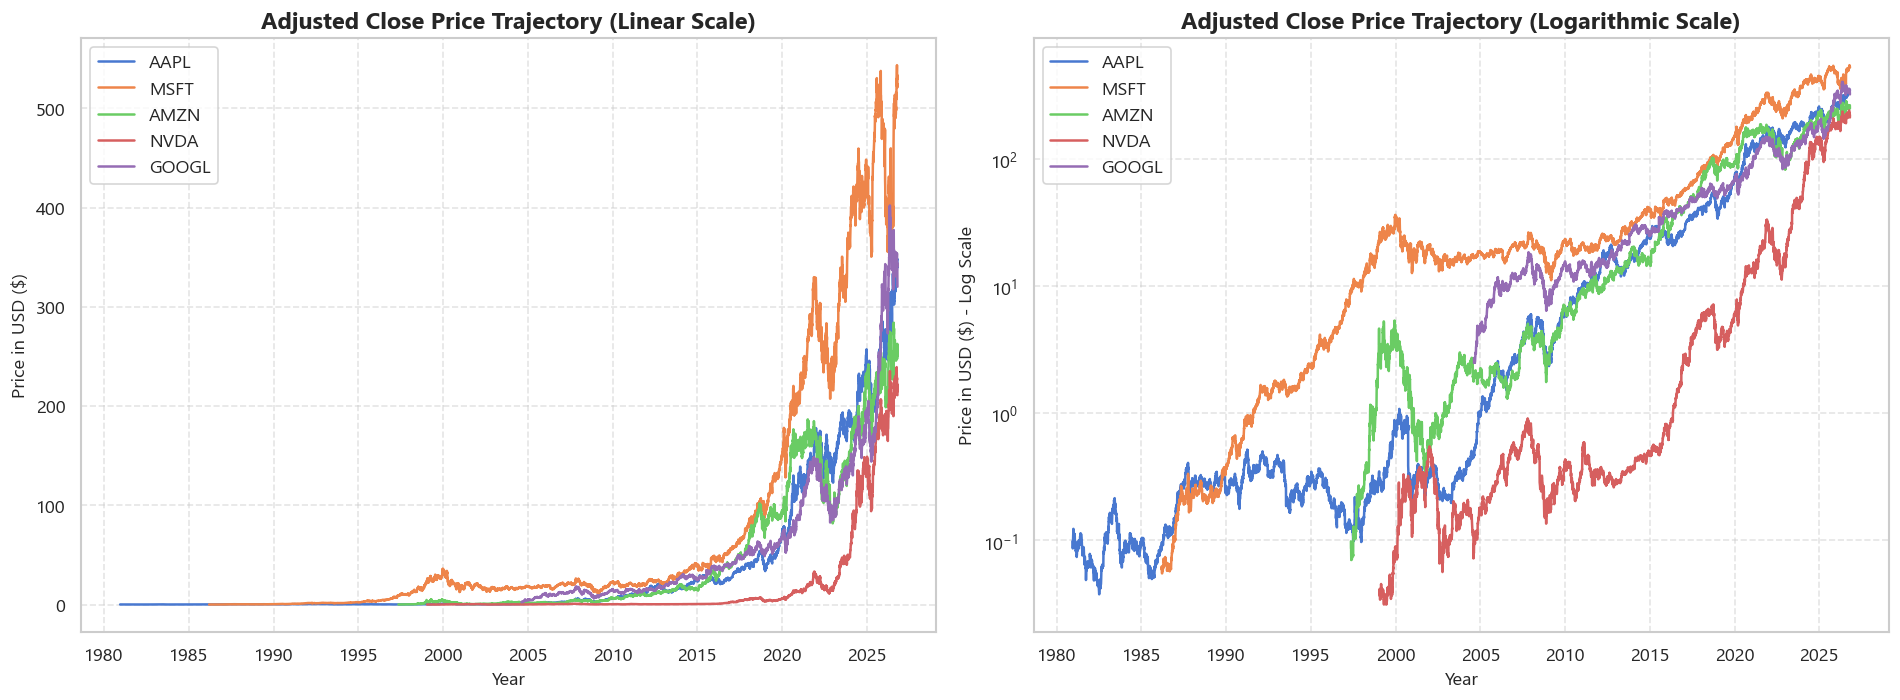

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Linear Scale
for ticker in df['Ticker'].unique():
    subset = df[df['Ticker'] == ticker]
    axes[0].plot(subset['Date'], subset['Adj Close'], label=ticker, linewidth=1.5)

axes[0].set_title("Adjusted Close Price Trajectory (Linear Scale)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Price in USD ($)")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Logarithmic Scale
for ticker in df['Ticker'].unique():
    subset = df[df['Ticker'] == ticker]
    axes[1].plot(subset['Date'], subset['Adj Close'], label=ticker, linewidth=1.5)

axes[1].set_yscale('log')
axes[1].set_title("Adjusted Close Price Trajectory (Logarithmic Scale)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Price in USD ($) - Log Scale")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
output_fig_path = Path('../reports/figures/01_price_trajectories.png')
if output_fig_path.parent.exists():
    plt.savefig(output_fig_path, dpi=200)
plt.show()

### 6.2 Daily Trading Volume & Liquidity Trends
Volume indicates the liquidity and market participation of an equity. High-volume periods often coincide with major earnings announcements, product releases, or market stress events (such as the 2008 Financial Crisis or the 2020 pandemic).


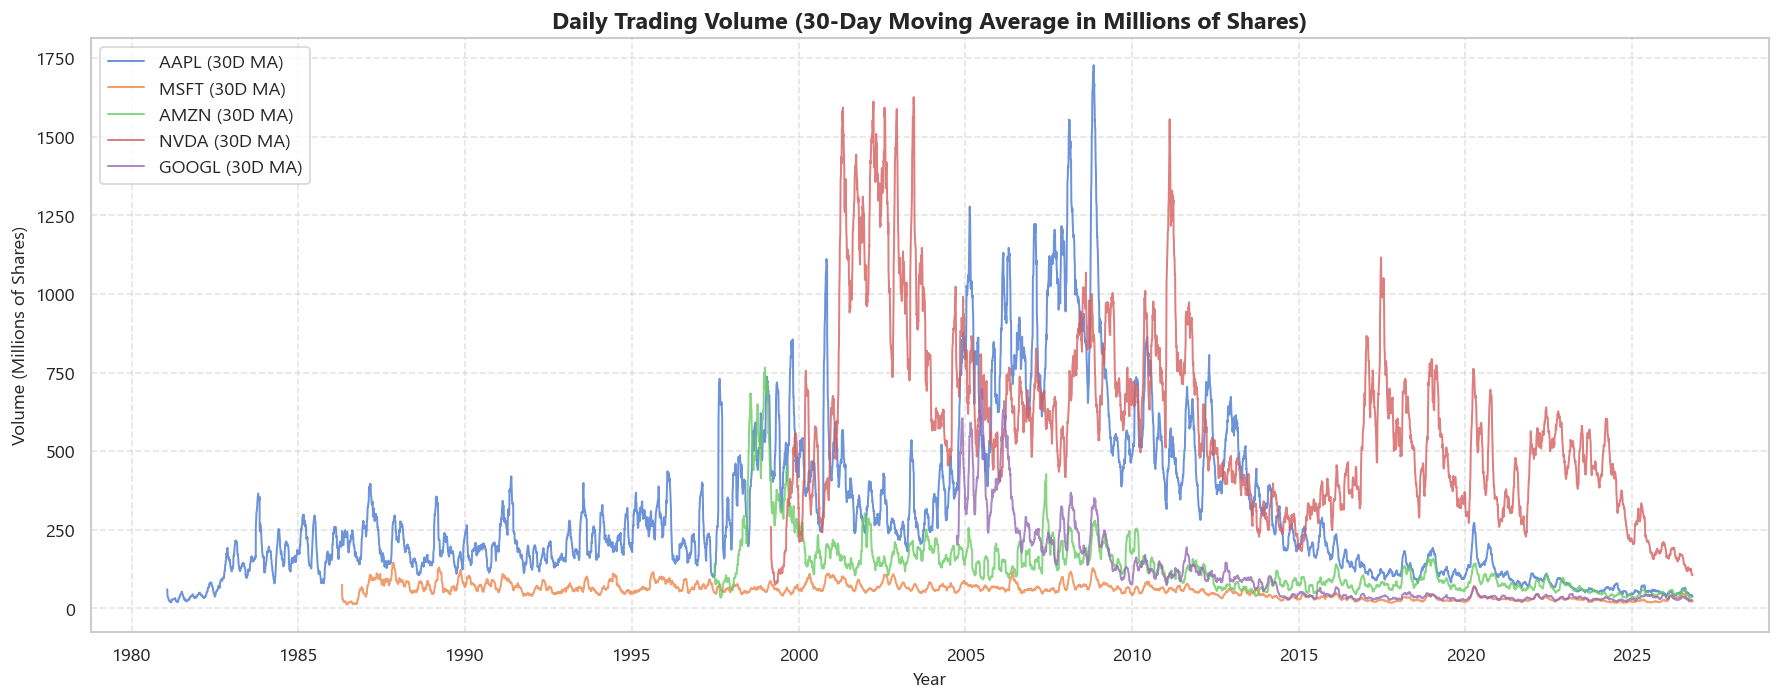

In [9]:
plt.figure(figsize=(15, 6))

for ticker in df['Ticker'].unique():
    subset = df[df['Ticker'] == ticker]
    # Apply a 30-day moving average to smooth extreme daily spikes
    smoothed_volume = subset['Volume'].rolling(window=30).mean()
    plt.plot(subset['Date'], smoothed_volume / 1e6, label=f"{ticker} (30D MA)", alpha=0.8, linewidth=1.2)

plt.title("Daily Trading Volume (30-Day Moving Average in Millions of Shares)")
plt.xlabel("Year")
plt.ylabel("Volume (Millions of Shares)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

vol_fig_path = Path('../reports/figures/02_trading_volume_trends.png')
if vol_fig_path.parent.exists():
    plt.savefig(vol_fig_path, dpi=200)
plt.show()


## 7. Preliminary Return & Risk Metric Calculation

In financial risk analysis, raw prices are non-stationary. Instead, we analyze **Daily Percentage Returns**:

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

Where $P_t$ is the `Adj Close` price on trading day $t$.


In [10]:
# Calculate daily percentage returns grouped by Ticker
df['Daily_Return'] = df.groupby('Ticker')['Adj Close'].pct_change()

# Display sample returns
df[['Date', 'Ticker', 'Adj Close', 'Daily_Return']].dropna().head(10)


,Date,Ticker,Adj Close,Daily_Return
1,1980-12-15,AAPL,0.0930,-0.0522
2,1980-12-16,AAPL,0.0862,-0.0734
3,1980-12-17,AAPL,0.0883,0.0248
4,1980-12-18,AAPL,0.0909,0.0290
5,1980-12-19,AAPL,0.0964,0.0610
6,1980-12-22,AAPL,0.1011,0.0487
7,1980-12-23,AAPL,0.1054,0.0422
8,1980-12-24,AAPL,0.1109,0.0526
9,1980-12-26,AAPL,0.1212,0.0923
10,1980-12-29,AAPL,0.1229,0.0141


### 7.1 Daily Return Distribution & Volatility Metrics
We compute standard financial statistics:
* **Mean Daily Return:** Average day-to-day percentage gain.
* **Daily Volatility (Std Dev):** Measure of market dispersion/risk.
* **Annualized Volatility:** $\sigma_{\text{daily}} \times \sqrt{252}$ (252 is the number of US trading days per year).
* **Skewness:** Asymmetry of the return distribution.
* **Kurtosis:** Tendency toward "fat tails" (extreme outliers / crash risks).


In [11]:
return_stats = df.groupby('Ticker')['Daily_Return'].agg(
    Count='count',
    Mean_Daily_Return='mean',
    Daily_Volatility='std',
    Min_Return='min',
    Max_Return='max',
    Skewness='skew',
    Kurtosis=lambda x: x.kurtosis()
).reset_index()

# Annualize metrics assuming 252 trading days per year
return_stats['Annualized_Return_Approx'] = return_stats['Mean_Daily_Return'] * 252
return_stats['Annualized_Volatility'] = return_stats['Daily_Volatility'] * np.sqrt(252)

display(return_stats)


,Ticker,Count,Mean_Daily_Return,Daily_Volatility,Min_Return,Max_Return,Skewness,Kurtosis,Annualized_Return_Approx,Annualized_Volatility
0,AAPL,11558,0.0011,0.0275,-0.5187,0.3323,-0.3645,18.7671,0.2750,0.4363
1,AMZN,7406,0.0016,0.0346,-0.2477,0.3447,1.0686,11.5820,0.4146,0.5488
2,GOOGL,5580,0.0011,0.0193,-0.1163,0.1999,0.6011,8.6282,0.2663,0.3070
3,MSFT,10232,0.0011,0.0209,-0.3012,0.1957,-0.0594,10.9063,0.2794,0.3323
4,NVDA,6981,0.0019,0.0372,-0.3523,0.4241,0.5968,11.4928,0.4852,0.5909


### 7.2 Return Distribution Histograms
Notice the bell-curve shape centered near 0% with extended tails representing black swan events and earnings surprises.


<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
C:\Users\booma\AppData\Local\Temp\ipykernel_51772\3673993126.py:6: SyntaxWarning: invalid escape sequence '\s'
  sns.kdeplot(subset, label=f"{ticker} ($\sigma$={subset.std():.3f})", linewidth=1.8)


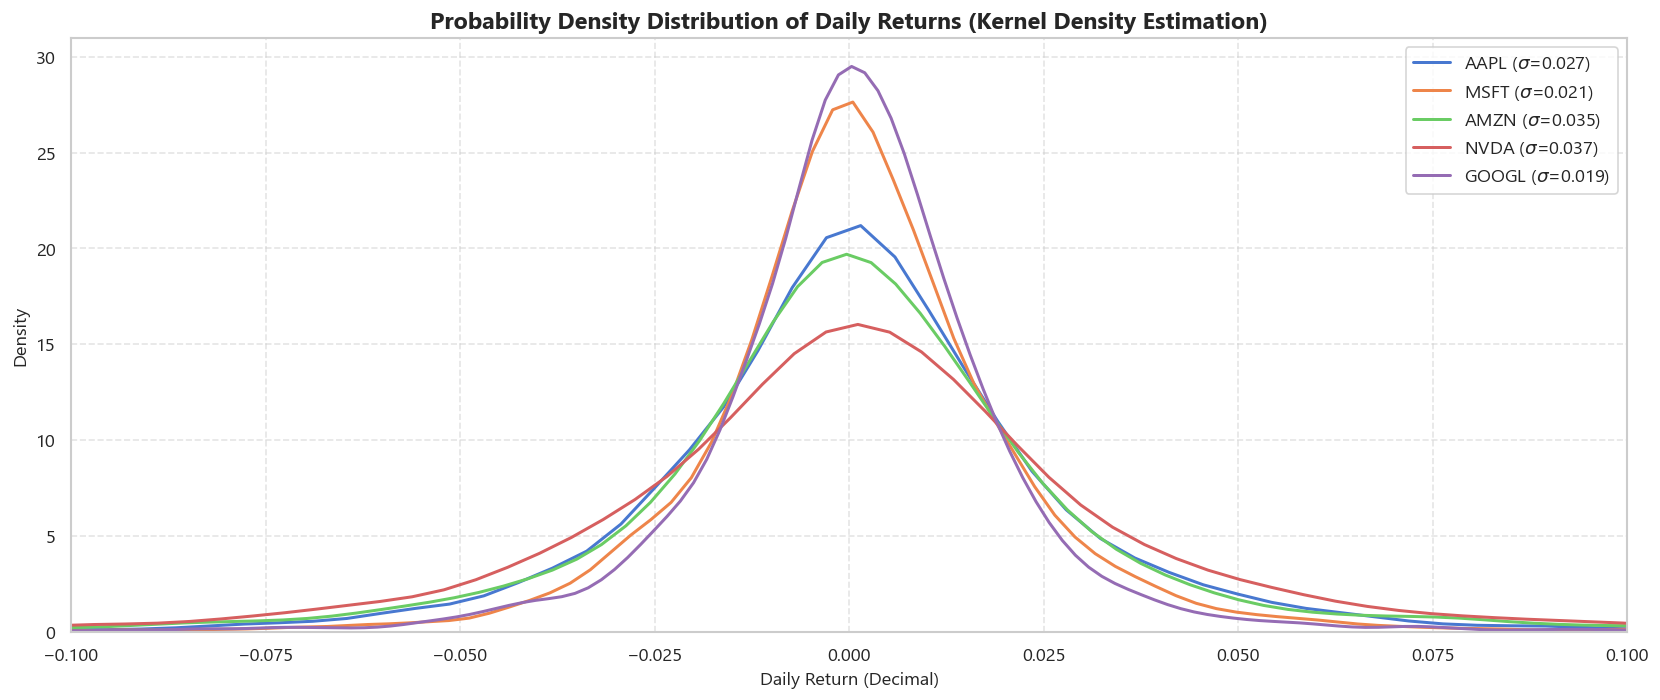

In [12]:
plt.figure(figsize=(14, 6))

for ticker in df['Ticker'].unique():
    subset = df[df['Ticker'] == ticker]['Daily_Return'].dropna()
    # Filter within -10% and +10% for clear visualization
    sns.kdeplot(subset, label=f"{ticker} ($\sigma$={subset.std():.3f})", linewidth=1.8)

plt.title("Probability Density Distribution of Daily Returns (Kernel Density Estimation)")
plt.xlabel("Daily Return (Decimal)")
plt.ylabel("Density")
plt.xlim(-0.10, 0.10)
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

dist_fig_path = Path('../reports/figures/03_return_distributions.png')
if dist_fig_path.parent.exists():
    plt.savefig(dist_fig_path, dpi=200)
plt.show()


## 8. Multi-Asset Correlation Analysis

In modern portfolio management (Markowitz Modern Portfolio Theory), **correlation** between assets is fundamental. Lower correlation allows an investor to diversify risk without sacrificing expected return.

To compute this accurately, we pivot the daily returns into a matrix where each column represents one stock, filtering to the overlapping period (since Google's IPO in 2004).


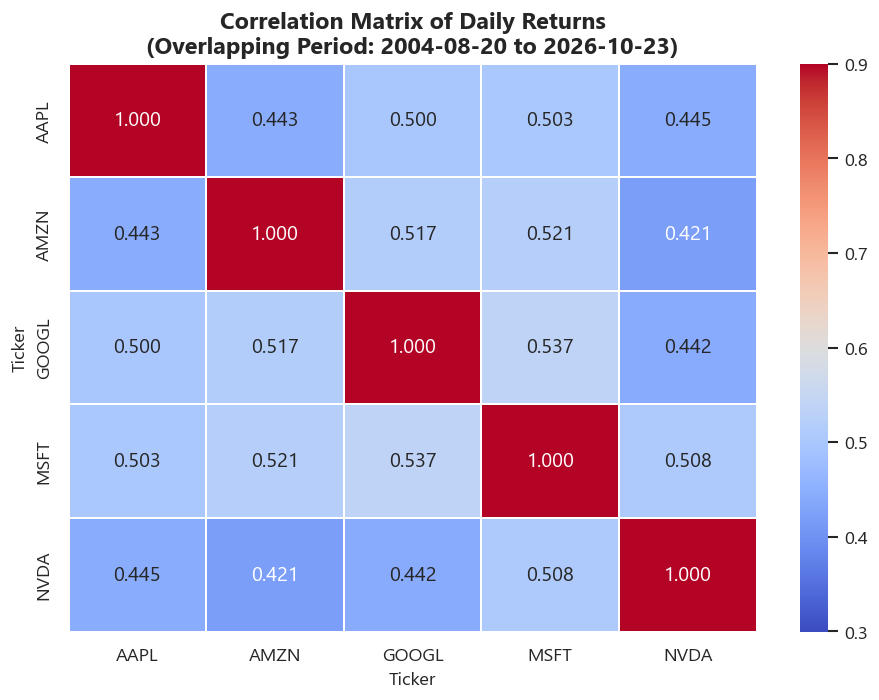

In [13]:
# Pivot daily returns into date-indexed multi-column format
returns_pivot = df.pivot(index='Date', columns='Ticker', values='Daily_Return')

# Drop rows where any stock has NaN (focusing on the shared period from 2004 onwards)
shared_returns = returns_pivot.dropna()

# Compute Pearson correlation matrix
corr_matrix = shared_returns.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=0.3, vmax=0.9, fmt=".3f", linewidths=1)
plt.title(f"Correlation Matrix of Daily Returns\n(Overlapping Period: {shared_returns.index.min().strftime('%Y-%m-%d')} to {shared_returns.index.max().strftime('%Y-%m-%d')})")
plt.tight_layout()

corr_fig_path = Path('../reports/figures/04_correlation_matrix.png')
if corr_fig_path.parent.exists():
    plt.savefig(corr_fig_path, dpi=200)
plt.show()


## 9. Key Findings & Analysis Roadmap

### Summary of Dataset Inspection:
1. **Pristine Data Quality:** 0 missing values across 41,762 trading observations spanning over 40+ years of tech market history.
2. **Temporal Breadth:** AAPL begins in 1980, MSFT in 1986, AMZN in 1997, NVDA in 1999, and GOOGL in 2004.
3. **Price Adjustments:** Corporate stock splits (e.g., Apple's 7-for-1 in 2014, NVIDIA's 10-for-1 in 2024) make `Adj Close` the strictly required metric for return calculations.
4. **Correlation Insight:** All five tech giants exhibit positive moderate-to-high correlation (~0.45 to ~0.65), reflecting shared systemic exposure to technological and macroeconomic cycles.

### Next Steps in This Project Portfolio:
* **Notebook 02:** Cumulative Returns, Compound Annual Growth Rate (CAGR), and Maximum Drawdown (MDD) during crisis periods (Dot-com Crash, 2008 GFC, 2020 COVID shock, 2022 Tech correction).
* **Notebook 03:** Risk-Adjusted Performance: Sharpe Ratio, Sortino Ratio, and Value at Risk (VaR).
* **Notebook 04:** Modern Portfolio Theory (MPT) & Monte Carlo Simulation: Constructing the **Markowitz Efficient Frontier** and optimal portfolio weightings.
